In [1]:
import os

base = "/kaggle/input/datasets/fifafootball/utrsynth-set-1"

# 1. what's directly inside the dataset folder?
print(os.listdir(base))

# 2. every file that is NOT an image
others = []
count = 0
for root, dirs, files in os.walk(base):
    for f in files:
        if f.lower().endswith(('.jpg', '.jpeg', '.png')):
            count += 1
        else:
            others.append(os.path.join(root, f))

print("images:", count)
print("non-image files:", others)

['UTRSet-Synth']
images: 20000
non-image files: ['/kaggle/input/datasets/fifafootball/utrsynth-set-1/UTRSet-Synth/labels.txt']


## **Checking Labels and Files**

In [2]:
base = "/kaggle/input/datasets/fifafootball/utrsynth-set-1/UTRSet-Synth"
label_path=base+"/labels.txt"

with open(label_path,encoding='utf-8') as f:
    lines=f.read().splitlines()

print("total lines : ",len(lines))
for l in lines[:5]:
    print(repr(l))

total lines :  20000
'0.jpg ملکوں مصرواپس بھاگتے کو ممکن وجوابب'
'1.jpg لکھنا رضا المذھب، البسطاء، ملائکہ'
'2.jpg سریمین واقعات نسان مدح موصوف فاصلے بجلی'
'3.jpg حذیفہ، سلطان'
'4.jpg وقد بعدامام مٹانے آتا 204 مروان کتھئی اتنا پھاڑ وفی'


'0.jpg ملکوں مصرواپس بھاگتے کو ممکن وجوابب'
'1.jpg لکھنا رضا المذھب، البسطاء، ملائکہ'
'2.jpg سریمین واقعات نسان مدح موصوف فاصلے بجلی'
'3.jpg حذیفہ، سلطان'


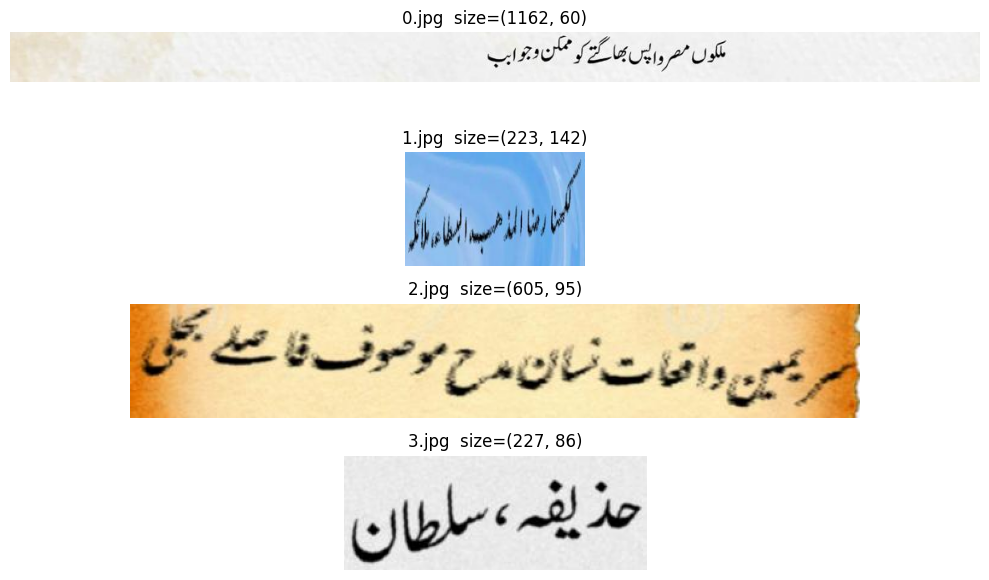

In [3]:
import matplotlib.pyplot as plt
from PIL import Image

fig, axes = plt.subplots(4, 1, figsize=(10, 6))
for ax, l in zip(axes, lines[:4]):
    print(repr(l))
    name = l.split()[0]            # we'll fix this once we see the format
    img = Image.open(f"{base}/{name}")
    ax.imshow(img)
    ax.set_title(f"{name}  size={img.size}")
    ax.axis("off")
plt.tight_layout()
plt.show()

## **measure the data and build the vocabulary**

In [4]:
names,texts=[],[]
for l in lines:
    name, text=l.split(' ',1)
    names.append(name)
    texts.append(text)

In [5]:
from PIL import Image
sizes=[Image.open(f"{base}/{n}").size for n in names[:2000]] #not all 20000 coz it would be waste of time
widths=[s[0] for s in sizes]
heights=[s[1] for s in sizes]
print("width  min/mean/max:", min(widths), sum(widths)/len(widths), max(widths))
print("height min/mean/max:", min(heights), sum(heights)/len(heights), max(heights))
#Why it matters: the model needs every image at the same height, and widths need to be handled in batches. These numbers tell us what height to pick and how wide the widest images get.

lens=[len(t) for t in texts]
print("label length min/mean/max:", min(lens), sum(lens)/len(lens), max(lens))

width  min/mean/max: 28 639.159 6493
height min/mean/max: 33 88.1235 190
label length min/mean/max: 1 33.8839 100


**Build Vocab**

In [6]:
chars=sorted(set("".join(texts))) #glues the 20000 labels into one huge string and keeps unique characters only
print("vocab size : ",len(chars))#puts them in sorted/fixed order so the numbering is sasme evertime we use it
print(chars)

vocab size :  111
[' ', '!', '"', "'", '(', ')', '*', '-', '.', '/', '0', '1', '2', '3', '4', '5', '6', '7', '8', '9', ':', '[', '\\', ']', '_', '{', '}', '،', '؍', 'ؔ', '؛', '؟', 'ء', 'آ', 'أ', 'ؤ', 'ئ', 'ا', 'ب', 'ة', 'ت', 'ث', 'ج', 'ح', 'خ', 'د', 'ذ', 'ر', 'ز', 'س', 'ش', 'ص', 'ض', 'ط', 'ظ', 'ع', 'غ', 'ف', 'ق', 'ك', 'ل', 'م', 'ن', 'ه', 'و', 'ي', 'ً', 'ٍ', 'َ', 'ُ', 'ِ', 'ّ', 'ْ', 'ٓ', 'ٔ', 'ٗ', '٠', '٤', '٥', 'ٰ', 'ٹ', 'پ', 'چ', 'ڈ', 'ڑ', 'ژ', 'ک', 'گ', 'ں', 'ھ', 'ہ', 'ۂ', 'ۃ', 'ی', 'ے', 'ۓ', '۔', '۰', '۱', '۲', '۳', '۴', '۵', '۶', '۷', '۸', '۹', '‘', '’', '“', '”']


In [7]:
from collections import Counter
counts=Counter("".join(texts))
print(counts.most_common()[-15:])

[('*', 67), ('ۂ', 56), ('ژ', 46), ('[', 40), ('٠', 33), (']', 29), ('_', 18), ('{', 18), ('}', 17), ('؛', 15), ('ٗ', 12), ('٤', 10), ('\\', 5), ('٥', 3), ('؍', 1)]


## **Dataset And DataLoaders**

**converts characters into numbers**

In [8]:
chars = sorted(set("".join(texts)))                        # unique characters in all labels, sorted
char2idx = {c: i + 1 for i, c in enumerate(chars)}         # character -> number, starting at 1 (0 is the blank)
idx2char = {i: c for c, i in char2idx.items()}             # number -> character
num_classes = len(chars) + 1                               # characters + the blank

print("vocab:", len(chars), "| classes:", num_classes)     # expect 37 and 38
print("longest label:", max(len(t) for t in texts))        # expect 51
print("max index:", max(char2idx.values()), "| min index:", min(char2idx.values()))   # expect 37 and 1

def encode(text):
    return [char2idx[c] for c in text]

vocab: 111 | classes: 112
longest label: 100
max index: 111 | min index: 1


**A Dataset tells PyTorch how to get item number i. It must have __len__ (how many items) and __getitem__ (what item i is).**

In [9]:
import numpy as np
import torch
from PIL import Image,ImageOps
from torch.utils.data import Dataset,DataLoader

IMG_H,IMG_W=64,1024

class UrduLineDataset(Dataset):
    def __init__(self,names,texts,base):
        self.names=names
        self.texts=texts
        self.base=base

    def __len__(self):
        return len(self.names)

    def __getitem__(self,i):
        img=Image.open(f"{self.base}/{self.names[i]}").convert("L") #converted to gray scale
        w,h=img.size #extract w,h
        new_w=min(IMG_W,max(1,round(w*IMG_H/h))) #new width : keeps the aspect ration, it scales the width by the same factor as height
        img=img.resize((new_w,IMG_H)) #resize the image
        img=ImageOps.mirror(img) #flip the image ,now the left side becomes urdu first letter and unused part on the right becomes white padding
        canvas=Image.new("L",(IMG_W,IMG_H),255) #canvas is a blank white 64x512 image, now every image has the same size
        canvas.paste(img,(0,0))
        x=torch.from_numpy(np.array(canvas)).float()/255.0 #converts the picture into tensors with values 0 and 1 (remember 0 for white and 1 for black)
        x=x.unsqueeze(0)#adds a channel dimension,pyTorch's CNN expects (channel,height,width)
        y=torch.tensor(encode(self.texts[i]),dtype=torch.long) #y= label as a tensor of numbes
        return x,y

**This function shows how to build a batch**

In [10]:
def collate(batch): #batch is a list of (x,y) pairs
    xs,ys=zip(*batch) #separates the batch into all images and all labels
    xs=torch.stack(xs) #stacks the images into one tensor with shape(batch,1,64,512)
    target_lengths=torch.tensor([len(y) for y in ys],dtype=torch.long)# records how long each label was so CTC knows where one label ends and where the next begins
    target=torch.cat(ys) #joins all the labels end to end into one long list,which is the fornat nn.CTCLoss accepts
    return xs,target,target_lengths

**Split And DataLoaders**

In [11]:
g=torch.Generator().manual_seed(42)#pyTorch Random Num generator
perm=torch.randperm(len(names),generator=g).tolist()#names=20K , shuffles the number 0-19999 in random order

train_idx=perm[:16000] #making range for training data
val_idx=perm[16000:18000] #checked after each epoch to see how training is going 
test_idx=perm[18000:] #test data

def make_ds(idx): #makes dataset
    return UrduLineDataset([names[i] for i in idx],[texts[i] for i in idx],base)

train_ds, val_ds, test_ds = make_ds(train_idx), make_ds(val_idx), make_ds(test_idx)

train_loader = DataLoader(train_ds, batch_size=32, shuffle=True, collate_fn=collate, num_workers=2)
val_loader=DataLoader(val_ds,batch_size=32,shuffle=False,collate_fn=collate,num_workers=2) #validation and test doesn't need shuffling since we are only measuring and not learning and a fixed order make the result repeatable
test_loader = DataLoader(test_ds, batch_size=32, shuffle=False, collate_fn=collate, num_workers=2)

#This is similar to train_test_split


**Checking it it works**

torch.Size([1, 64, 1024]) torch.Size([43])
گا۔!“ گی، فعلاً، ہیم، ہونی انسان صفحہ قنسول


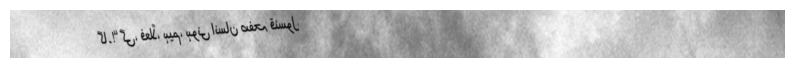

torch.Size([32, 1, 64, 1024]) torch.Size([1099]) tensor([58, 48, 49, 35, 13])


In [12]:
import matplotlib.pyplot as plt

x, y = train_ds[0]
print(x.shape, y.shape)
print("".join(idx2char[int(i)] for i in y))
plt.figure(figsize=(10, 2))
plt.imshow(x[0], cmap="gray")
plt.axis("off")
plt.show()

xs, targets, tl = next(iter(train_loader))
print(xs.shape, targets.shape, tl[:5])

## **CNN Hgelper and the Model**

In [13]:
import torch.nn as nn

def conv_block(in_ch,out_ch,pool):
    return nn.Sequential(
        nn.Conv2d(in_ch,out_ch,kernel_size=3,padding=1),#in_ch: how many channels come in,out_ch how many feature map cameout, padding=1 adds a border of zeros so 3x3 filter doesn't shrink the image
        #slides a 3x3 filter over the image(CNN wali shit)
        nn.BatchNorm2d(out_ch),#normalizes values in each batch to make training faster
        nn.ReLU(),#applies relu
        nn.MaxPool2d(pool),#pooling of 2x2
    )

**Create CRNN**

In [14]:
class CRNN(nn.Module):                                   # every PyTorch model inherits from nn.Module
    def __init__(self, num_classes):                     # num_classes = 38 (37 characters + CTC blank)
        super().__init__()                               # set up the parent class (required)

        self.cnn = nn.Sequential(                        # CNN: image -> feature maps
            conv_block(1,   32,  (2, 2)),                # 1 -> 32 channels, halve height and width
            conv_block(32,  64,  (2, 2)),                # 32 -> 64 channels, halve height and width
            conv_block(64,  128, (2, 1)),                # 64 -> 128 channels, halve height only
            conv_block(128, 256, (2, 1)),                # 128 -> 256 channels, halve height only
            conv_block(256, 256, (2, 1)),                # 256 -> 256 channels, halve height only
        )

        self.rnn = nn.LSTM(                              # BiLSTM: reads the slices as a sequence
            input_size=512,                              # each slice is a vector of 512 numbers
            hidden_size=256,                             # LSTM memory size per direction
            num_layers=2,                                # two LSTM layers stacked
            bidirectional=True,                          # read left-to-right and right-to-left
            batch_first=True,                            # data layout is (batch, slices, features)
            dropout=0.2,                                 # randomly drop 20% between layers to reduce overfitting
        )

        self.fc = nn.Linear(512, num_classes)            # 512 numbers per slice -> 38 character scores

    def forward(self, x):                                # runs when you call model(images)
        x = self.cnn(x)                                  # (B, 1, 64, 512) -> (B, 256, 2, 128)
        b, c, h, w = x.shape                             # unpack the four sizes into names
        x = x.reshape(b, c * h, w)                       # merge channels and height: (B, 512, 128)
        x = x.permute(0, 2, 1)                           # swap to (B, 128 slices, 512 features)
        x, _ = self.rnn(x)                               # BiLSTM output: (B, 128, 512); final state ignored
        x = self.fc(x)                                   # scores per slice: (B, 128, 38)
        return x                                         # B images, 128 slices, 38 scores each

**Testing with Fake data**

In [15]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")   # pick the GPU if there is one, else CPU
model = CRNN(num_classes).to(device)                     # build the model (38 classes) and move it to that device

dummy = torch.randn(4, 1, 64, 1024).to(device)            # 4 fake images of random noise: (batch, channels, height, width)
out = model(dummy)                                       # forward pass: calls model.forward(dummy)
print(out.shape)                                         # expect torch.Size([4, 128, 38]) = 4 images, 128 slices, 38 scores

print("parameters:", sum(p.numel() for p in model.parameters()))   # count every learnable number in the model

torch.Size([4, 256, 112])
parameters: 4190768


**CTC Loss on a tiny fake example**

In [16]:
import torch
import torch.nn as nn

ctc= nn.CTCLoss(blank=0,zero_infinity=True)
#blank=0 matches what se set up earliear : number 0 is the blank
#zero infinity=True: handles samples that CTC can't possibly match(for example an image with fewer slices than label characters)
#without it one bad sample turns the whole loss into inf and ruin training

In [17]:
T, C = 10, 5                                   # 10 slices, 5 classes (blank + 4 characters)
path = [1, 1, 0, 2, 2, 0, 3, 0, 0, 0]          # what we pretend the model predicts per slice: C C _ A A _ T _ _ _

logits = torch.full((T, 1, C), -10.0)          # start with very low scores everywhere; shape (T, N, C)
for t, k in enumerate(path):
    logits[t, 0, k] = 10.0                     # give a very high score to the class in `path` at each slice
log_probs = logits.log_softmax(2)              # turn scores into log-probabilities (over the class dimension)

targets = torch.tensor([1, 2, 3])              # the true label: C A T
input_lengths = torch.tensor([T])              # the model produced 10 slices
target_lengths = torch.tensor([3])             # the label has 3 characters

print(ctc(log_probs, targets, input_lengths, target_lengths))

wrong = torch.tensor([3, 2, 1])                # T A C instead of C A T
print(ctc(log_probs, wrong, input_lengths, target_lengths))

tensor(0.)
tensor(19.6338)


**Test 2**

In [18]:
xs, targets, target_lengths = next(iter(train_loader))   # one real batch of 32 images and labels
xs = xs.to(device)                                       # move the images to the GPU

out = model(xs)                                          # (32, 128, 38): batch, slices, classes
log_probs = out.log_softmax(2).permute(1, 0, 2)          # log-probabilities, reordered to (128, 32, 38)

input_lengths = torch.full((xs.size(0),), out.size(1), dtype=torch.long)   # 32 copies of 128: every sample has 128 slices

loss = ctc(log_probs, targets, input_lengths, target_lengths)
print("loss:", loss.item())

loss: 66.18070983886719


In [19]:
print(len(names), len(texts))                        # should be 20000 20000
print(len(train_idx), len(val_idx), len(test_idx))   # should be 16000 2000 2000
print(len(train_ds.names), len(train_ds))            # should be 16000 16000

20000 20000
16000 2000 2000
16000 16000


**Training Loop**

In [20]:
from torch.utils.data import Subset

small_ds = Subset(train_ds,range(100)) #only the first 100 training samples
small_loader = DataLoader(small_ds,batch_size=25,shuffle=True,
                collate_fn=collate,num_workers=2) #4 barches of 25 per epoch

model= CRNN(num_classes).to(device) #fresh , untrained model
optimizer=torch.optim.Adam(model.parameters(),lr=1e-3) #Adam updates all the model's weights ; lr=step size
ctc=nn.CTCLoss(blank=0,zero_infinity=True)# same loss as in the tests

In [31]:
for epoch in range(1,301): #150 passes over the 100 images
    model.train() #training mode
    total_loss=0.0

    for xs,targets,target_lengths in small_loader: #one batch
        xs=xs.to(device) #images to the GPU
        out=model(xs)
        log_probs=out.log_softmax(2).permute(1,0,2)#log-probs, reordering to (128, B, 38) for CTC
        input_lengths=torch.full((xs.size(0),),out.size(1),dtype=torch.long) # every sample has 128 slices

        loss=ctc(log_probs,targets,input_lengths,target_lengths) #how wrong the model is
        optimizer.zero_grad() #clear gradients left over from last step
        loss.backward() #back propagation : compute how to change each weight
        torch.nn.utils.clip_grad_norm_(model.parameters(),5) # gradients can get too large so we gave to scale them,cap huge gradients CTC can spike
        optimizer.step() #update the weights

        total_loss+=loss.item() #add this batch loss to total_loss

    if epoch % 10 ==0:
        print(f"epoch {epoch:3d}  loss {total_loss / len(small_loader):.4f}")

epoch  10  loss 4.0878
epoch  20  loss 3.8469
epoch  30  loss 3.7451
epoch  40  loss 3.6570
epoch  50  loss 3.6478


KeyboardInterrupt: 

In [21]:
model = CRNN(num_classes).to(device)                              # fresh model, so earlier NaN weights are gone
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)         # same optimizer as before

xs, targets, target_lengths = next(iter(small_loader))            # one batch: images, joined labels, label lengths

print("images have nan:", torch.isnan(xs).any().item())           # True would mean the data itself is broken
print("pixel min/max:", xs.min().item(), xs.max().item())         # should be within 0 to 1
print("label min/max:", targets.min().item(), targets.max().item(), "| num_classes:", num_classes)   # min should be 1 or more, max under 38
print("longest label:", target_lengths.max().item())              # should be at most 51

xs = xs.to(device)                                                # images to the GPU

for step in range(10):                                            # 10 training steps on the same batch
    out = model(xs)                                               # raw scores (B, 128, 38)
    log_probs = out.log_softmax(2).permute(1, 0, 2)               # log-probs in (128, B, 38) order for CTC
    input_lengths = torch.full((xs.size(0),), out.size(1), dtype=torch.long)   # every sample has 128 slices
    loss = ctc(log_probs, targets, input_lengths, target_lengths) # how wrong the model is

    optimizer.zero_grad()                                         # clear old gradients
    loss.backward()                                               # compute gradients
    gn = torch.nn.utils.clip_grad_norm_(model.parameters(), 5)    # clip, and return the gradient size before clipping
    print(step, "loss", loss.item(), "| grad norm", gn.item(), "| output has nan:", torch.isnan(out).any().item())
    optimizer.step()                                              # update the weights

images have nan: False
pixel min/max: 0.0 1.0
label min/max: 1 111 | num_classes: 112
longest label: 80
0 loss 48.95681381225586 | grad norm 17.316160202026367 | output has nan: False
1 loss 37.65981674194336 | grad norm 46.1894645690918 | output has nan: False
2 loss 20.33860969543457 | grad norm 62.85220718383789 | output has nan: False
3 loss 7.455488204956055 | grad norm 37.068111419677734 | output has nan: False
4 loss 4.502441883087158 | grad norm 2.4040539264678955 | output has nan: False
5 loss 4.750738620758057 | grad norm 10.724099159240723 | output has nan: False
6 loss 4.700511932373047 | grad norm 11.903748512268066 | output has nan: False
7 loss 4.382219314575195 | grad norm 10.748703956604004 | output has nan: False
8 loss 4.008896827697754 | grad norm 7.245649814605713 | output has nan: False
9 loss 3.808896064758301 | grad norm 1.1570067405700684 | output has nan: False


## **Add The metric**


**The problem: the model gives 128 slices, and each slice has 112 scores (one per class). We want a string, not scores.The idea: for each slice, pick the class with the highest score. Then apply the CTC rule: merge repeats, then remove blanks.Worked example with 10 slices (class 0 is the blank, shown as _):slices:  ح  ح  _  ذ  ذ  _  ی  _  _  _Merge consecutive repeats: ح _ ذ _ ی _Remove blanks: حذی**


### **The Decoder**

In [22]:
def greedy_decode(out): #raw scores,shape(B,128,112)
    best=out.argmax(2)# for each slice,the class with the highest score (B->128)
    results=[] #one decode string per image
    for seq in best.tolist(): #takes one image's 128 classs numbers as a plain list
        decoded=[] #characters we keep for this image
        prev=0 #prev slice's class ; star as blank
        for k in seq:#go through the 128 slices in order
            if k!=prev and k!=0: #keep only if it changed from previous slice and isn't a blank
                decoded.append(idx2char[k]) #number-> character
            prev=k                      #remember this slice for next comparison
        results.append("".join(decoded)) #join the characters into a string
    return results

### **Edit Distance and CER**


**Edit distance counts the fewest single-character changes (insert, delete, replace) needed to turn string a into string b. For example, cat to cut is 1 (replace a with u), and cat to cats is 1 (insert s).How the code finds it: it fills a table where the cell for (i, j) answers “how many edits to turn the first i letters of a into the first j letters of b?” We only need the previous row to compute the next one, so we keep just two rows**


**CER is the total edits across all images divided by the total number of true characters. If the true text has 100 characters in total and we need 8 edits, CER is 0.08, meaning 8% of characters are wrong. zip(preds, refs) pairs each prediction with its true text.**

In [23]:
def edit_distance(a, b):                         # minimum edits to turn string a into string b
    prev_row = list(range(len(b) + 1))           # cost of building each prefix of b from an empty a
    for i, ca in enumerate(a, 1):                # go through a's characters, counting from 1
        row = [i]                                # turning a[:i] into an empty b costs i deletions
        for j, cb in enumerate(b, 1):            # go through b's characters
            row.append(min(
                prev_row[j] + 1,                 # delete ca
                row[j - 1] + 1,                  # insert cb
                prev_row[j - 1] + (ca != cb),    # replace (cost 0 if the characters already match)
            ))
        prev_row = row                           # this row becomes the previous row
    return prev_row[-1]                          # cost of turning all of a into all of b

def cer(preds, refs):                            # preds = predicted strings, refs = true strings
    edits = sum(edit_distance(p, r) for p, r in zip(preds, refs))   # total edits over all pairs
    total = sum(len(r) for r in refs)                               # total true characters
    return edits / total                                            # errors per true character

**Running the mode over a loader**

In [24]:
def evaluate(model, loader):
    model.eval()                                 # eval mode: turns off dropout, fixes BatchNorm
    preds, refs = [], []                         # predicted strings and true strings
    with torch.no_grad():                        # no gradients needed, which saves memory and time
        for xs, targets, target_lengths in loader:
            out = model(xs.to(device))           # scores for this batch
            preds += greedy_decode(out)          # add this batch's predictions
            for y in torch.split(targets, target_lengths.tolist()):   # cut the joined label list back into one label per image
                refs.append("".join(idx2char[int(i)] for i in y))     # numbers -> true text
    return cer(preds, refs), preds, refs

score, preds, refs = evaluate(model, small_loader)   # test on the 100 images we trained on
print("CER:", score)
for p, r in list(zip(preds, refs))[:3]:              # show 3 examples
    print("pred:", p)
    print("true:", r)
    print()

CER: 1.0
pred: 
true: السَّمَاءِ وَأَغْرَقْنَا اللَّهِ أَنفُسُكُمُ آمَنُوا

pred: 
true: ومناظرہ ادائیگی سینہ نعمتیں 447 الوجہ سام

pred: 
true: رہا، اور رکی مانگوں۔



## **Full Training Run**

### **Training setup**


**Fresh model and optimizer. The earlier model only memorized 100 images, so we start over.Validation CER every epoch. Training loss only shows the model fitting data it has seen. Validation CER shows how it does on images it hasn’t seen, which is the number that matters.Saving the best checkpoint. The last epoch isn’t always the best one. We keep the weights from the epoch with the lowest validation CER.Learning-rate scheduler. When validation CER stops improving, it halves the learning rate. Smaller steps help the model settle into a better solution.History lists. We store the numbers each epoch so we can plot the curves afterward.**


In [25]:
import time

model=CRNN(num_classes).to(device) #builds new untrained model on GPU
optimizer= torch.optim.Adam(model.parameters(),lr=1e-3)
scheduler=torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer,mode='min',factor=0.5,patience=2)
#ReducePLROnPlateau watches a number we feed it each epoch
#mode = "min" means lower is better
#patience=2 it means it waits 2 epochs without improvement 
#factor = 0.5 then halves the learning rae
EPOCHS=60
best_cer=float('inf')
history={"train_loss" : [],"val_cer" :[]} #history holds two empty lists that we fill as we go


### **Training loop with validation**

In [ ]:
for epoch in range(1,EPOCHS+1): #30 epochs
    t0=time.time() #starts time so we can track how long an epcoh takes
    model.train() #switches to training mode
    total_loss=0.0

    for xs,targets,target_lengths in train_loader:
        xs=xs.to(device)
        out=model(xs)
        log_probs=out.log_softmax(2).permute(1,0,2)
        input_lengths=torch.full((xs.size(0),),out.size(1),dtype=torch.long)
        loss=ctc(log_probs,targets,input_lengths,target_lengths)
    
        optimizer.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(),5)
        optimizer.step()
    
        total_loss+=loss.item()
    
    train_loss=total_loss/len(train_loader)
    val_cer,_,_=evaluate(model,val_loader)
    
    history["train_loss"].append(train_loss)
    history["val_cer"].append(val_cer)
    
    if val_cer<best_cer:
        best_cer=val_cer
        torch.save(model.state_dict(),"/kaggle/working/best_crnn.pt")
    print(f"epoch {epoch:2d} | train loss {train_loss:.4f} | val CER {val_cer:.4f} | best {best_cer:.4f} | {time.time()-t0:.0f}s")

### **Loss and CER curves**

In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 2, figsize=(10, 3))
ax[0].plot(history["train_loss"]); ax[0].set_title("train loss")
ax[1].plot(history["val_cer"]);    ax[1].set_title("validation CER")
plt.show()

## **Evaluate And Analyze Erors**

**Load the best weights**

In [26]:
model = CRNN(num_classes).to(device)                      # build an empty model with the same architecture
state = torch.load("/kaggle/input/notebooks/fifafootball/notebooka9acf8a134/best_crnn.pt", map_location=device)   # read the saved weights file
model.load_state_dict(state)                              # copy the saved numbers into the model
model.eval()                                              # evaluation mode: dropout off

CRNN(
  (cnn): Sequential(
    (0): Sequential(
      (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
      (3): MaxPool2d(kernel_size=(2, 2), stride=(2, 2), padding=0, dilation=1, ceil_mode=False)
    )
    (1): Sequential(
      (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
      (3): MaxPool2d(kernel_size=(2, 2), stride=(2, 2), padding=0, dilation=1, ceil_mode=False)
    )
    (2): Sequential(
      (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
      (3): MaxPool2d(kernel_size=(2, 1), stride=(2, 1), padding=0, dilation=1, ceil_mode=False)
    )
    (3): Sequential(
      (0): Conv2d(128, 2

**Test Score**

In [27]:
test_cer, preds, refs = evaluate(model, test_loader)      # run the Step 8 function on the 2,000 test images
print("test CER:", round(test_cer, 4))                    # characters wrong per true character
print("exact matches:", sum(p == r for p, r in zip(preds, refs)) / len(refs))   # share of lines with zero mistakes

test CER: 0.1983
exact matches: 0.2365


**Worst Predictions**

In [28]:
errors = [(edit_distance(p, r) / max(len(r), 1), p, r) for p, r in zip(preds, refs)]   # CER per line, with prediction and truth
errors.sort(reverse=True)                                 # worst lines first
for e, p, r in errors[:8]:                                # print the 8 worst
    print(f"{e:.2f}\npred: {p}\ntrue: {r}\n")

1.33
pred: ت  ۱
true: ۱۶۶

1.00
pred: ۸
true: ۷۱

1.00
pred: ۷۹ *
true: 5 ۷۸

1.00
pred: ۷
true: ۱

1.00
pred: ۶2.ح
true: 293 ۱۸

1.00
pred: ۵0
true: ۹۱

1.00
pred: ۲۹۵
true: ۶۳ 9

1.00
pred: ۱
true: 1



**Does Length Matters?**

In [29]:
import numpy as np

lens = np.array([len(r) for r in refs])                   # true length of every test line
errs = np.array([edit_distance(p, r) for p, r in zip(preds, refs)])   # number of edits for every line

for lo, hi in [(0, 15), (15, 30), (30, 45), (45, 200)]:   # four length groups
    m = (lens >= lo) & (lens < hi)                        # True for lines inside this group
    if m.sum():
        print(f"length {lo}-{hi}: {m.sum()} lines | CER {errs[m].sum() / lens[m].sum():.3f}")

length 0-15: 471 lines | CER 0.127
length 15-30: 425 lines | CER 0.108
length 30-45: 450 lines | CER 0.137
length 45-200: 654 lines | CER 0.252


**Which Characters Get Confused**

In [30]:
from difflib import SequenceMatcher
from collections import Counter

det5kosub/, missed, extra = Counter(), Counter(), Counter()      # wrong letter, dropped letter, invented letter

for p, r in zip(preds, refs):
    for tag, i1, i2, j1, j2 in SequenceMatcher(None, r, p).get_opcodes():   # align truth r with prediction p
        if tag == "replace" and (i2 - i1) == (j2 - j1):   # same-length swap: letter A became letter B
            for a, b in zip(r[i1:i2], p[j1:j2]):
                sub[(a, b)] += 1
        elif tag == "delete":                             # in the truth but missing from the prediction
            for a in r[i1:i2]:
                missed[a] += 1
        elif tag == "insert":                             # in the prediction but not in the truth
            for b in p[j1:j2]:
                extra[b] += 1

print("most confused (true -> predicted):", sub.most_common(10))
print("most missed:", missed.most_common(8))
print("most invented:", extra.most_common(8))

SyntaxError: invalid syntax (1370341723.py, line 4)

In [31]:
import os
real_root = "/kaggle/input/datasets/fifafootball/utrset-real/UTRSet-Real"            # folder of the attached dataset
for r, d, f in os.walk(real_root):                        # list folders and sample files
    print(r, len(d), "folders,", len(f), "files", f[:3])

/kaggle/input/datasets/fifafootball/utrset-real/UTRSet-Real 2 folders, 0 files []
/kaggle/input/datasets/fifafootball/utrset-real/UTRSet-Real/test 1 folders, 1 files ['gt.txt']
/kaggle/input/datasets/fifafootball/utrset-real/UTRSet-Real/test/test 0 folders, 2096 files ['017_005_19.jpg', '017_004_5.jpg', '017_003_0.jpg']
/kaggle/input/datasets/fifafootball/utrset-real/UTRSet-Real/train 1 folders, 1 files ['gt.txt']
/kaggle/input/datasets/fifafootball/utrset-real/UTRSet-Real/train/test 0 folders, 9065 files ['110_021_12.jpg', '024_006_33.jpg', '043_018_3.jpg']


In [33]:
real_root = "/kaggle/input/datasets/fifafootball/utrset-real/UTRSet-Real"   # dataset root
with open(real_root + "/test/gt.txt", encoding="utf-8") as f:                # the test split's labels
    lines = f.read().splitlines()                                            # one string per line
print("test lines:", len(lines))                                             # expect ~2096
for l in lines[:3]:                                                          # show the format
    print(repr(l))                                                           # repr shows tabs and spaces

test lines: 2096
'test/051_016_0.jpg\tمل سکتا ہے،’’'
'test/051_016_1.jpg\tلفظوں کی یہی عظمت اور ان کی بہی شاہانہ مقام ہے جسے'
'test/051_016_2.jpg\tپہچان کر عہد الزبتھ کے ڈراما نگاروں اور خصوساً شیکسپیر نے ڈرامے'


In [34]:
def load_split(split):                                                        # split = "test" or "train"
    folder  = f"{real_root}/{split}"                                          # holds gt.txt
    img_dir = f"{folder}/test"                                                # images are in the nested test folder
    with open(f"{folder}/gt.txt", encoding="utf-8") as f:
        raw = f.read().splitlines()
    names, texts, dropped = [], [], 0
    for l in raw:
        parts = l.split('\t', 1) if '\t' in l else l.split(' ', 1)            # split on tab if present, else first space
        if len(parts) != 2:                                                   # skip blank or malformed lines
            continue
        name, text = parts
        name = name.split('/')[-1]                                            # drop any "test/" prefix in the name
        if all(c in char2idx for c in text):                                  # keep only lines our vocab knows
            names.append(name); texts.append(text)
        else:
            dropped += 1                                                      # would crash encode() otherwise
    print(split, "kept:", len(names), "| dropped:", dropped)
    return names, texts, img_dir

rn, rt, real_img_dir = load_split("test")                                     # test split: images the model has never seen
real_ds = UrduLineDataset(rn, rt, real_img_dir)                               # same Dataset class as before
real_loader = DataLoader(real_ds, batch_size=32, shuffle=False, collate_fn=collate, num_workers=2)

test kept: 2096 | dropped: 0


In [35]:
real_cer, rp, rr = evaluate(model, real_loader)                               # Step 8 evaluate() on the real scans
print("UTRSet-Real CER (no fine-tuning):", round(real_cer, 4))                # the honest synthetic-to-real gap

UTRSet-Real CER (no fine-tuning): 0.2979


In [36]:
real_root = "/kaggle/input/datasets/fifafootball/utrset-real/UTRSet-Real"   # dataset root

# --- debug: show the raw format of the first 3 train lines ---
with open(real_root + "/train/gt.txt", encoding="utf-8") as f:
    raw = f.read().splitlines()
for l in raw[:3]:
    print(repr(l))                                              # repr shows tabs / odd spaces
print("---")

def load_split(split):                                          # split = "test" or "train"
    folder  = f"{real_root}/{split}"                            # holds gt.txt
    img_dir = f"{folder}/test"                                  # images are in the nested test/ folder
    with open(f"{folder}/gt.txt", encoding="utf-8") as f:
        raw = f.read().splitlines()
    names, texts, dropped = [], [], 0
    for l in raw:
        parts = l.split(None, 1)                                # split on ANY whitespace, once
        if len(parts) != 2:                                     # skip blank / glued lines
            dropped += 1
            continue
        name, text = parts[0], parts[1]
        if not name.lower().endswith((".jpg", ".jpeg", ".png")):# sanity check: name must be an image file
            dropped += 1
            continue
        if all(c in char2idx for c in text):                    # only keep lines our vocab knows
            names.append(name); texts.append(text)
        else:
            dropped += 1
    print(split, "kept:", len(names), "| dropped:", dropped)
    return names, texts, img_dir

rn, rt, real_img_dir  = load_split("test")                      # 2096 real test images
real_ds     = UrduLineDataset(rn, rt, real_img_dir)
real_loader = DataLoader(real_ds, batch_size=32, shuffle=False, collate_fn=collate, num_workers=2)

tn, tt, train_img_dir = load_split("train")                     # 9065 real train images
k = int(0.8 * len(tn))                                          # 80% fine-tune, 20% held out
ft_ds = UrduLineDataset(tn[:k], tt[:k], train_img_dir)
te_ds = UrduLineDataset(tn[k:], tt[k:], train_img_dir)
ft_loader = DataLoader(ft_ds, batch_size=32, shuffle=True,  collate_fn=collate, num_workers=2)
te_loader = DataLoader(te_ds, batch_size=32, shuffle=False, collate_fn=collate, num_workers=2)
print("fine-tune:", len(ft_ds), "| held-out:", len(te_ds))

'test/076_022_18.jpg\tاندراج و تحریر شرعاً صرف مستحب اور پسندیدہ ہے وہ واجب نہیں کہ کسی شرعی'
'test/076_022_16.jpg\tاور ہندوستان کی مسلم ریاستوں میں اس پر کم و بیش عمل درآمد بھی ہے، جہاں تک جبری'
'test/076_022_15.jpg\tبلکہ اس کے نزدیک وہ پسندیدہ اور مستحسن بھی ہے، عملی پہلوکے لحاظ سے اسلامی سلطنتوں'
---
test kept: 2096 | dropped: 0
train kept: 9022 | dropped: 43
fine-tune: 7217 | held-out: 1805


In [37]:
real_root = "/kaggle/input/datasets/fifafootball/utrset-real/UTRSet-Real"

def load_split(split):
    folder  = f"{real_root}/{split}"
    img_dir = f"{folder}/test"
    with open(f"{folder}/gt.txt", encoding="utf-8") as f:
        raw = f.read().splitlines()
    names, texts, dropped = [], [], 0
    for l in raw:
        parts = l.split(None, 1)
        if len(parts) != 2:
            dropped += 1; continue
        name, text = parts
        name = name.split('/')[-1]                             # <-- strip "test/" prefix from filename
        if not name.lower().endswith((".jpg", ".jpeg", ".png")):
            dropped += 1; continue
        if all(c in char2idx for c in text):
            names.append(name); texts.append(text)
        else:
            dropped += 1
    print(split, "kept:", len(names), "| dropped:", dropped)
    return names, texts, img_dir

rn, rt, real_img_dir  = load_split("test")
real_ds     = UrduLineDataset(rn, rt, real_img_dir)
real_loader = DataLoader(real_ds, batch_size=32, shuffle=False, collate_fn=collate, num_workers=2)

tn, tt, train_img_dir = load_split("train")
k = int(0.8 * len(tn))
ft_ds = UrduLineDataset(tn[:k], tt[:k], train_img_dir)
te_ds = UrduLineDataset(tn[k:], tt[k:], train_img_dir)
ft_loader = DataLoader(ft_ds, batch_size=32, shuffle=True,  collate_fn=collate, num_workers=2)
te_loader = DataLoader(te_ds, batch_size=32, shuffle=False, collate_fn=collate, num_workers=2)
print("fine-tune:", len(ft_ds), "| held-out:", len(te_ds))

test kept: 2096 | dropped: 0
train kept: 9022 | dropped: 43
fine-tune: 7217 | held-out: 1805


In [38]:
# after the loop, model holds the LAST epoch's weights
# reload the best if you want:
# model.load_state_dict(torch.load("/kaggle/working/best_crnn_real.pt", map_location=device))
model.eval()
real_cer_ft, rp_ft, rr_ft = evaluate(model, real_loader)     # the same 2096 test images
print("UTRSet-Real CER after fine-tune:", round(real_cer_ft, 4))   # compare with 0.2979
print("exact matches:", sum(p == r for p, r in zip(rp_ft, rr_ft)) / len(rr_ft))

UTRSet-Real CER after fine-tune: 0.2979
exact matches: 0.04770992366412214


image : /kaggle/input/datasets/fifafootball/utrset-real/UTRSet-Real/test/test/038_215_12.jpg
true  : (۸ ۴)جعفر بن عیسیٰ نے ایک اچھے حسین خط کی طرف دیکھا اور کہا :
predicted: (۴۸) جعفر بن یحییا نے ایک اچہے ’حسین خط کی طرف دیکھا اور کہا:


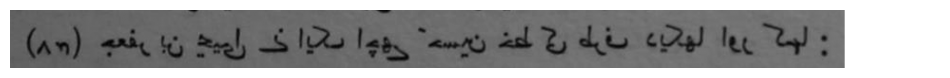

'(۴۸) جعفر بن یحییا نے ایک اچہے ’حسین خط کی طرف دیکھا اور کہا:'

In [39]:
import torch
from PIL import Image, ImageOps
import numpy as np

def predict_image(path, show=True):
    """Load one image from disk, run the model, return and (optionally) display the predicted text."""
    IMG_H, IMG_W = 64, 1024                                 # must match training

    img = Image.open(path).convert("L")                     # grayscale, same as training
    w, h = img.size
    new_w = min(IMG_W, max(1, round(w * IMG_H / h)))        # keep aspect ratio, cap at canvas
    img = img.resize((new_w, IMG_H))
    img = ImageOps.mirror(img)                              # flip: Urdu reads right-to-left

    canvas = Image.new("L", (IMG_W, IMG_H), 255)            # white canvas
    canvas.paste(img, (0, 0))
    x = torch.from_numpy(np.array(canvas)).float().div(255).unsqueeze(0).unsqueeze(0)  # (1, 1, 64, 1024)

    model.eval()
    with torch.no_grad():
        out = model(x.to(device))                           # (1, T, C)
        best = out.argmax(2)[0].tolist()                    # best class per slice

    # CTC greedy decode: collapse repeats, drop blanks (class 0)
    text, prev = [], None
    for k in best:
        if k != prev and k != 0:
            text.append(idx2char[k])
        prev = k
    pred = "".join(text)

    print("predicted:", pred)
    if show:
        import matplotlib.pyplot as plt
        plt.figure(figsize=(12, 2))
        plt.imshow(canvas, cmap="gray"); plt.axis("off"); plt.show()
    return pred


# ---- run it on a random real test image ----
import random
i = random.randrange(len(rn))                               # random index into the real test set
sample_path = f"{real_img_dir}/{rn[i]}"

print("image :", sample_path)
print("true  :", rt[i])
predict_image(sample_path)

predicted: (دپاکتان سندھ کےامیدوار انیکشن میں حصہ یں گے۔)


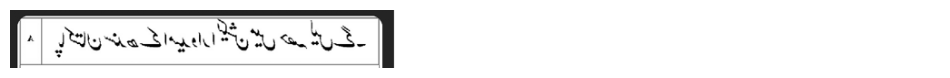

'(دپاکتان سندھ کےامیدوار انیکشن میں حصہ یں گے۔)'

In [40]:
predict_image("/kaggle/input/datasets/fifafootball/random-image/Screenshot 2026-10-16 223459.png")

predicted: میرا ناق سعد پے


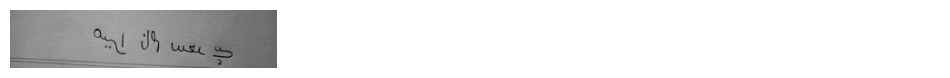

'میرا ناق سعد پے'

In [41]:
predict_image("/kaggle/input/datasets/fifafootball/handwritten-text/handwritten text.jpeg")

In [42]:
import json
json.dump(chars, open("/kaggle/working/chars.json", "w", encoding="utf-8"), ensure_ascii=False)

In [44]:
# Load your v1 CRNN (64 x 1024 input) from saved weights. Put these next to this script / notebook:
#   best_crnn_real.pt  (fine-tuned, CER 0.2842 on real)  or  best_crnn.pt (synthetic only, CER 0.2979 on real)
#   chars.json         (the character list, see step 2)
import json
import numpy as np
import torch, torch.nn as nn
from PIL import Image, ImageOps

IMG_H, IMG_W = 64, 1024                                   # must match training
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

chars = json.load(open("chars.json", encoding="utf-8"))   # same list, same order as training
char2idx = {c: i + 1 for i, c in enumerate(chars)}        # 0 = CTC blank
idx2char = {i: c for c, i in char2idx.items()}
num_classes = len(chars) + 1

def conv_block(in_ch, out_ch, pool):
    return nn.Sequential(nn.Conv2d(in_ch, out_ch, 3, padding=1), nn.BatchNorm2d(out_ch),
                         nn.ReLU(), nn.MaxPool2d(pool))

class CRNN(nn.Module):                                    # identical to your training class
    def __init__(self, num_classes):
        super().__init__()
        self.cnn = nn.Sequential(conv_block(1, 32, (2, 2)), conv_block(32, 64, (2, 2)),
                                 conv_block(64, 128, (2, 1)), conv_block(128, 256, (2, 1)),
                                 conv_block(256, 256, (2, 1)))
        self.rnn = nn.LSTM(512, 256, num_layers=2, bidirectional=True, batch_first=True, dropout=0.2)
        self.fc = nn.Linear(512, num_classes)
    def forward(self, x):
        x = self.cnn(x)
        b, c, h, w = x.shape
        x = x.reshape(b, c * h, w).permute(0, 2, 1)
        x, _ = self.rnn(x)
        return self.fc(x)

model.load_state_dict(torch.load("/kaggle/input/notebooks/fifafootball/notebooka9acf8a134/best_crnn.pt", map_location=device))   # change the file name if needed
model.eval()                                              # inference mode (no dropout, fixed BatchNorm)

def predict_image(path):
    img = Image.open(path).convert("L")
    w, h = img.size
    new_w = min(IMG_W, max(1, round(w * IMG_H / h)))
    img = ImageOps.mirror(img.resize((new_w, IMG_H)))
    canvas = Image.new("L", (IMG_W, IMG_H), 255)
    canvas.paste(img, (0, 0))
    x = torch.from_numpy(np.array(canvas)).float().div(255).unsqueeze(0).unsqueeze(0)
    with torch.no_grad():
        best = model(x.to(device)).argmax(2)[0].tolist()
    text, prev = [], 0
    for k in best:                                        # CTC greedy decode: merge repeats, drop blanks
        if k != prev and k != 0:
            text.append(idx2char[k])
        prev = k
    return "".join(text)

# print(predict_image("some_line.jpg"))

In [45]:
import glob
print(glob.glob("/kaggle/input/**/best_crnn.pt", recursive=True))
print(glob.glob("/kaggle/input/**/chars.json", recursive=True))

['/kaggle/input/notebooks/fifafootball/notebooka9acf8a134/best_crnn.pt']
[]


In [46]:
import random
real_root = "/kaggle/input/datasets/fifafootball/utrset-real/UTRSet-Real"
rows = [l.split(None, 1) for l in open(f"{real_root}/test/gt.txt", encoding="utf-8").read().splitlines()]
rows = [r for r in rows if len(r) == 2]
for name, truth in random.sample(rows, 5):
    path = f"{real_root}/test/test/{name.split('/')[-1]}"
    print("TRUE:", truth)
    print("PRED:", predict_image(path))
    print()

TRUE: وہ سڑک پر خون میں لت پت
PRED: وہ سڑک پرخون میں لت پت

TRUE: باپ
PRED: باپ

TRUE: تلووں پر بید برسانے شروع کئے۔
PRED: تلدِدں پرہید برمانے شررع کے۔

TRUE: مفتی سید محمد عباس صاحب اور رئیس المتکلمین مولانا السیّد حامد حسین صاحب اعلیٰ اللہ مقامہم ایسے بزرگو ارو نسلے
PRED: انہسفتی سیدیعباسصاحاب رریلکلمینہولاناالسیّدحا حمسین صاحبداعلیٰ یشرمقاہریسےبزرگرڑِم)

TRUE: رنگینی میں کتنا قریبی اور ایک حد تک لازم وملزوم کا تعلق ہے۔
PRED: لگینی یںکتثاتیاادرایکی ھاتا لازم دملزرم کاتعلتی ہے۔

